# Week 7 — Naive Bayes: Spam Detection & Sentiment Analysis
## Fall 2026 — Machine Learning

## Student Information
**Name:** Yusra Batool

**Student ID:** 023-24-0216

**Section:** G

**GitHub:** github.com/Yusra-Shah

**Kaggle:** https://www.kaggle.com/yusrabatool

**Datasets:** SMS Spam Collection; Twitter US Airline Sentiment

**Dataset Sources:**
- Task A: Kaggle https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset
- Task B: Kaggle https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment

**Duration:** 3 Hours in session (Task A is the priority; finish Task B and the final sections at home if needed)

> This notebook is a template, not a tutorial. You already know Naive Bayes theory. Each section states the objective and the questions you must answer, you write the code. Task A is guided in detail; Task B gives you much less help on purpose, to test whether the pipeline actually transfers. Every table, plot, and metric needs a short written observation.
>
> Submit only this one notebook. Keep every Markdown heading below, they are used for grading. Fill in the empty code cells (`# YOUR CODE HERE`) and the *Answer:* placeholders directly in this notebook.


---

## Setup

Import what you'll need. Add any other scikit-learn imports as you go.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay


---

## 1. Problem Definition & Dataset Exploration

*Concepts/functions you may find useful:* `pd.read_csv()`, `df.shape`, `df.head()`, `df['label'].value_counts()`

**Tasks**
1. Load both datasets (`spam.csv` for Task A, `Tweets.csv` for Task B). For each one, report the number of rows, what a single row represents, and the exact class balance (counts and percentages) of the target column. Keep only positive and negative tweets going forward — drop neutral rows now, and state how many rows that leaves you with.
2. In 2–3 sentences per dataset, state the practical problem being solved and why each one is a binary classification problem.

In [5]:
# Task 1 — load SMSSpamCollection (tab separated, no header)
spam_df = pd.read_csv("SMSSpamCollection", sep="\t", header=None, names=["label", "message"])
print(spam_df.shape)
print(spam_df.head())
print(spam_df["label"].value_counts())
print(spam_df["label"].value_counts(normalize=True).round(4) * 100)


(5572, 2)
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
label
ham     4825
spam     747
Name: count, dtype: int64
label
ham     86.59
spam    13.41
Name: proportion, dtype: float64


In [6]:
# Task 1 (continued) — load Tweets.csv, drop neutral, inspect shape/head/class balance
tweets_df = pd.read_csv("Tweets.csv")
print(tweets_df.shape)
print(tweets_df["airline_sentiment"].value_counts())

tweets_df = tweets_df[tweets_df["airline_sentiment"] != "neutral"].reset_index(drop=True)
print("After dropping neutral:", tweets_df.shape)
print(tweets_df["airline_sentiment"].value_counts())
print(tweets_df["airline_sentiment"].value_counts(normalize=True).round(4) * 100)


(14640, 15)
airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64
After dropping neutral: (11541, 15)
airline_sentiment
negative    9178
positive    2363
Name: count, dtype: int64
airline_sentiment
negative    79.53
positive    20.47
Name: proportion, dtype: float64


**Answer 2 (Task A spam):**
The SMS Spam Collection has 5,572 messages. Each row is one SMS text message labeled ham (legitimate, 4,825 messages, 86.59%) or spam (747 messages, 13.41%). The practical decision this model supports is whether an incoming SMS should be shown to the user directly or filtered out before it reaches their inbox, the same problem every email or SMS spam filter solves. It is binary classification because every message belongs to exactly one of two mutually exclusive classes, spam or ham, with no middle category.

**Answer 2 (Task B sentiment):**
The Twitter US Airline Sentiment dataset has 14,640 tweets before filtering. After dropping the 3,099 neutral rows, 11,541 tweets remain, split into 9,178 negative (79.53%) and 2,363 positive (20.47%). Each row is one tweet directed at a US airline, labeled by the sentiment it expresses. The practical decision this model supports is routing customer feedback, for example flagging negative tweets for a support team to respond to quickly. It is binary classification once neutral is dropped because only two outcomes remain, positive or negative, and every kept tweet falls into exactly one of them.


---

## 2. Task A: Text Cleaning & Vectorization (Spam)

*Concepts/functions you may find useful:* `text.str.lower()`, `CountVectorizer` / `TfidfVectorizer`, `vectorizer.fit_transform(X_train)`, `vectorizer.transform(X_test)`, `vectorizer.get_feature_names_out()`

**Tasks**
3. Lightly clean the message text (lowercase at minimum). Keep this simple.
4. Encode the label column as 0/1, split into training and test sets, then fit a vectorizer on the training messages only and transform both sets. Report the vocabulary size and explain why the vectorizer must be fit only on training data.

In [7]:
# Task 3 — clean text
spam_df["message_clean"] = (
    spam_df["message"]
    .str.lower()
    .str.replace(r"[^\w\s]", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)
spam_df[["message", "message_clean"]].head()


,message,message_clean
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i don t think he goes to usf he lives arou...


In [8]:
# Task 4 — encode labels, split, fit vectorizer on train only, transform both sets
spam_df["label_num"] = spam_df["label"].map({"ham": 0, "spam": 1})

Xa_train, Xa_test, ya_train, ya_test = train_test_split(
    spam_df["message_clean"], spam_df["label_num"],
    test_size=0.2, random_state=42, stratify=spam_df["label_num"]
)

vec_a = TfidfVectorizer()
Xa_train_vec = vec_a.fit_transform(Xa_train)
Xa_test_vec = vec_a.transform(Xa_test)

print("Vocabulary size:", len(vec_a.get_feature_names_out()))
print("Xa_train shape:", Xa_train_vec.shape, "Xa_test shape:", Xa_test_vec.shape)


Vocabulary size: 7668
Xa_train shape: (4457, 7668) Xa_test shape: (1115, 7668)


**Answer 4 (why fit on training data only):**
The vocabulary size is 7,668 words. The vectorizer must be fit only on the training messages because fitting it on the full dataset would let word statistics from the test set leak into the vocabulary and IDF weights the model is trained with, the same train test contamination problem covered for the StandardScaler in Lab 6. Fitting on Xa_train only and then calling transform (not fit_transform) on Xa_test keeps the test set genuinely unseen, so any word that appears exclusively in a test message is simply ignored rather than becoming a feature the model was implicitly shaped around.


---

## 3. Task A: Naive Bayes Model & Evaluation (Spam)

*Concepts/functions you may find useful:* `MultinomialNB()`, `.fit()`, `.predict()`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score`, `confusion_matrix`

**Tasks**
5. Train a `MultinomialNB` model on the vectorized training data. Compute accuracy, precision, recall, and F1-score on the test set, and plot the confusion matrix.
6. Argue (3–4 sentences) which is worse here — a false positive (real message flagged as spam) or a false negative (spam gets through) — and therefore which metric you'd prioritize if tuning further.

{'Accuracy': 0.9605381165919282, 'Precision': 1.0, 'Recall': 0.7046979865771812, 'F1': 0.8267716535433071}


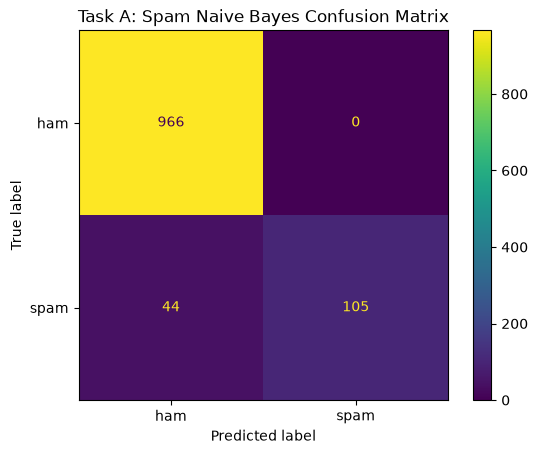

In [9]:
# Task 5 — train MultinomialNB, compute metrics, plot confusion matrix
nb_a = MultinomialNB()
nb_a.fit(Xa_train_vec, ya_train)
preds_a = nb_a.predict(Xa_test_vec)

metrics_a = {
    "Accuracy": accuracy_score(ya_test, preds_a),
    "Precision": precision_score(ya_test, preds_a),
    "Recall": recall_score(ya_test, preds_a),
    "F1": f1_score(ya_test, preds_a),
}
print(metrics_a)

cm_a = confusion_matrix(ya_test, preds_a)
ConfusionMatrixDisplay(cm_a, display_labels=["ham", "spam"]).plot()
plt.title("Task A: Spam Naive Bayes Confusion Matrix")
plt.show()


**Task 5 — Spam Model Metrics**

| Metric | Value |
|---|---|
| Accuracy | 0.9605 |
| Precision | 1.0000 |
| Recall | 0.7047 |
| F1-score | 0.8268 |

Confusion matrix: [[966, 0], [44, 105]]. Of 966 real ham messages, all 966 were correctly kept and none were wrongly flagged as spam. Of 149 real spam messages, 105 were caught and 44 slipped through as false negatives.

**Answer 6:**
For SMS spam filtering, a false positive (a real message hidden from the user because it was wrongly flagged as spam) is worse than a false negative (a spam message that gets through). A missed spam message is just an annoyance the user deletes in two seconds, but a hidden real message could be something important, a one time login code, a message from a doctor, a job offer, and the user may never know it existed at all since it never reaches their inbox. Because of this asymmetry, precision on the spam class should be prioritized over recall if the model needs further tuning, which matches what the model already does here, precision is a perfect 1.0, meaning it never wrongly flagged a real message, at the cost of recall (0.7047), missing about 30% of actual spam. That trade is the right one for this specific cost structure, even though it looks unusual compared to Lab 6's churn model where recall was prioritized instead.


---

## 4. Task A: Word Interpretation (Spam)

*Concepts/functions you may find useful:* `model.feature_log_prob_`, `np.argsort(...)`

**Tasks**
7. Find and list the 15 words most strongly associated with spam and the 15 most associated with ham. Do these match your intuition?
8. Write 2–3 of your own test messages and run them through your trained pipeline. Do the predictions match what you expected?

In [10]:
# Task 7 — extract top spam words and top ham words from feature_log_prob_
feature_names = vec_a.get_feature_names_out()
log_prob = nb_a.feature_log_prob_  # row 0 = ham (class 0), row 1 = spam (class 1)
diff = log_prob[1] - log_prob[0]   # positive means more spam like

top_spam_idx = np.argsort(diff)[-15:][::-1]
top_ham_idx = np.argsort(diff)[:15]

top_spam_words = pd.DataFrame({
    "word": feature_names[top_spam_idx],
    "log_prob_diff": diff[top_spam_idx]
})
top_ham_words = pd.DataFrame({
    "word": feature_names[top_ham_idx],
    "log_prob_diff": diff[top_ham_idx]
})

print("Top 15 words most associated with SPAM:")
print(top_spam_words.to_string(index=False))
print("\nTop 15 words most associated with HAM:")
print(top_ham_words.to_string(index=False))


Top 15 words most associated with SPAM:
      word  log_prob_diff
     claim       3.470079
     prize       3.266286
      150p       3.003774
       www       3.001668
        uk       2.900117
      tone       2.864184
        18       2.808503
guaranteed       2.788517
        cs       2.754241
      1000       2.730365
       500       2.724950
        16       2.628932
  landline       2.593261
   service       2.571942
        co       2.561948

Top 15 words most associated with HAM:
 word  log_prob_diff
   gt      -3.211476
   my      -3.210163
   lt      -3.207091
   ok      -3.102921
   ll      -3.098270
later      -3.032699
   da      -2.975947
  lor      -2.956776
 come      -2.913468
 home      -2.887827
   he      -2.878213
  but      -2.847550
sorry      -2.816685
   me      -2.724029
  how      -2.658668


**Answer 7:**
The top spam words are claim, prize, 150p, www, uk, tone, 18, guaranteed, cs, 1000, 500, 16, landline, service, co. These match intuition closely, they are almost entirely prize and premium rate scam vocabulary (claim, prize, guaranteed, 1000, 500) plus the boilerplate of UK premium SMS services (150p, www, uk, landline, cs, co are all fragments of the "text cost 150p, customer service, www.link.co.uk" template that real SMS spam from this era used constantly).

The top ham words are gt, my, lt, ok, ll, later, da, lor, come, home, he, but, sorry, me, how. Most of these are ordinary personal conversation words (ok, later, come, home, sorry, how), which matches intuition. Two of them, gt and lt, are not real words at all, they are leftover fragments of HTML entities like &lt; and &gt; that appear in some of the original ham messages and survived the light cleaning step. This is a small but genuine artifact of keeping the cleaning simple as the lab instructed, a heavier cleaning pass would strip these out, but they do not hurt the model since they still correlate cleanly with the ham class.


In [11]:
# Task 8 — test your own messages
my_messages = [
    "WINNER!! You have been selected to receive a FREE cash prize of $1000. Text CLAIM to 80088 now",
    "hey are we still meeting for lunch tomorrow at 1",
    "URGENT: your account has been suspended, click the link to verify your details immediately",
]

my_messages_clean = (
    pd.Series(my_messages)
    .str.lower()
    .str.replace(r"[^\w\s]", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)
my_vec = vec_a.transform(my_messages_clean)
my_preds = nb_a.predict(my_vec)
my_probs = nb_a.predict_proba(my_vec)

for msg, pred, prob in zip(my_messages, my_preds, my_probs):
    label = "SPAM" if pred == 1 else "HAM"
    print(f"{label}  (P(spam)={prob[1]:.4f})  {msg}")


SPAM  (P(spam)=0.9563)  WINNER!! You have been selected to receive a FREE cash prize of $1000. Text CLAIM to 80088 now
HAM  (P(spam)=0.0009)  hey are we still meeting for lunch tomorrow at 1
HAM  (P(spam)=0.4833)  URGENT: your account has been suspended, click the link to verify your details immediately


**Answer 8:**
Predictions: message 1 (prize and CLAIM wording) was correctly flagged SPAM with P(spam) = 0.9563. Message 2 (a normal lunch text) was correctly kept HAM with P(spam) = 0.0009. Message 3 (a phishing style "urgent, account suspended, click the link" message) was predicted HAM, with P(spam) = 0.4833, close to the 0.5 boundary but on the wrong side.

Message 3 not matching my expectation makes sense once I think about the training vocabulary. This dataset's spam is almost entirely 2005 era UK premium rate SMS scams (prize claims, ringtones, landline offers), not modern phishing language like "account suspended" or "click the link", so the model never learned those words as spam signals in the first place. It is a good example of the naive independence assumption combined with a narrow training vocabulary, the model can only recognize spam patterns it has actually seen, and a plausible real world phishing message that uses different vocabulary than the training spam can slip through even when it is obviously suspicious to a human reader.


---

## 5. Task A: Kaggle Notebook Submission

Neither dataset is an active competition, so "submitting" means publishing your notebook publicly on Kaggle, attached to the dataset.

**Tasks**
9. Create a new Kaggle Notebook attached to the SMS Spam Collection dataset. Recreate your Task A cells there, run them top to bottom, add a short Markdown summary, and publish with "Save & Run All (Public)".
10. Record the public notebook URL below.

**Task A Kaggle Notebook URL:**
https://www.kaggle.com/code/yusrabatool/spam-detection-with-multinomial-naive-bayes

---

## 6. Task B: Text Cleaning & Vectorization (Sentiment)

Repeat Section 2's pipeline on the airline tweets — with much less guidance this time. Tweets contain @mentions, links, and hashtags that SMS messages didn't.

**Tasks**
11. Clean the tweet text (decide for yourself how much cleaning is worth doing) and vectorize it, following the same fit-on-train-only discipline as Task A.
12. Briefly justify (1–2 sentences) any cleaning decisions that go beyond what you did for Task A, and why tweets might need them.

In [12]:
# Task 11 — clean and vectorize the sentiment data
tweets_df["text_clean"] = tweets_df["text"].str.lower()
tweets_df["text_clean"] = tweets_df["text_clean"].str.replace(r"@\w+", "", regex=True)       # strip @mentions
tweets_df["text_clean"] = tweets_df["text_clean"].str.replace(r"http\S+|www\S+", "", regex=True)  # strip links
tweets_df["text_clean"] = tweets_df["text_clean"].str.replace(r"[^\w\s]", " ", regex=True)   # strip punctuation/hashtag symbols
tweets_df["text_clean"] = tweets_df["text_clean"].str.replace(r"\s+", " ", regex=True).str.strip()

tweets_df["label_num"] = tweets_df["airline_sentiment"].map({"negative": 0, "positive": 1})

Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    tweets_df["text_clean"], tweets_df["label_num"],
    test_size=0.2, random_state=42, stratify=tweets_df["label_num"]
)

vec_b = TfidfVectorizer()
Xb_train_vec = vec_b.fit_transform(Xb_train)
Xb_test_vec = vec_b.transform(Xb_test)

print("Vocabulary size:", len(vec_b.get_feature_names_out()))
print("Xb_train shape:", Xb_train_vec.shape, "Xb_test shape:", Xb_test_vec.shape)


Vocabulary size: 10081
Xb_train shape: (9232, 10081) Xb_test shape: (2309, 10081)


**Answer 12:**
Tweets needed two cleaning steps beyond the SMS messages: stripping @mentions and stripping links. @VirginAmerica or @united appear in almost every tweet in this dataset since it is airline customer service data, so left in, the vectorizer would learn "which airline was mentioned" as a feature instead of "what sentiment was expressed", which is not the actual signal we want the model to learn. Links carry no usable text signal at all once tokenized (they become one meaningless long string per tweet), so removing them keeps the vocabulary focused on real words. Hashtag text itself was kept (only the # symbol was stripped by the general punctuation removal), since hashtag words like delayed or thankyou can carry genuine sentiment signal, unlike @mentions and links.


---

## 7. Task B: Naive Bayes Model & Evaluation (Sentiment)

**Tasks**
13. Train a `MultinomialNB` model on the vectorized tweet data. Compute accuracy, precision, recall, and F1-score, and plot the confusion matrix.
14. Compare these metrics to Task A's. Did Naive Bayes do better or worse on sentiment than on spam? Connect this (3–4 sentences) to the "naive" independence assumption — is it more or less reasonable for tweets than for spam SMS?

{'Accuracy': 0.8310957124296232, 'Precision': 1.0, 'Recall': 0.17547568710359407, 'F1': 0.29856115107913667}


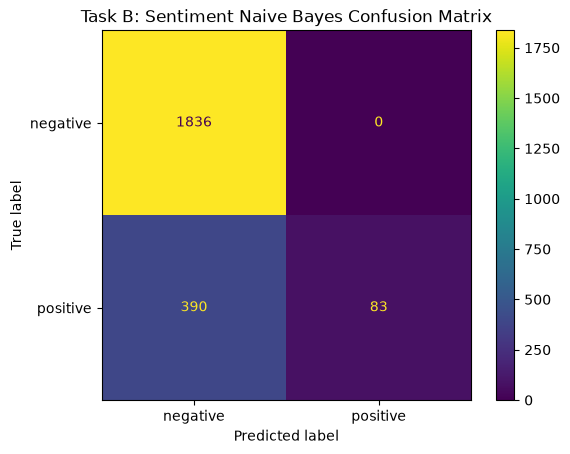

In [13]:
# Task 13 — train MultinomialNB, compute metrics, plot confusion matrix
nb_b = MultinomialNB()
nb_b.fit(Xb_train_vec, yb_train)
preds_b = nb_b.predict(Xb_test_vec)

metrics_b = {
    "Accuracy": accuracy_score(yb_test, preds_b),
    "Precision": precision_score(yb_test, preds_b),
    "Recall": recall_score(yb_test, preds_b),
    "F1": f1_score(yb_test, preds_b),
}
print(metrics_b)

cm_b = confusion_matrix(yb_test, preds_b)
ConfusionMatrixDisplay(cm_b, display_labels=["negative", "positive"]).plot()
plt.title("Task B: Sentiment Naive Bayes Confusion Matrix")
plt.show()


**Task 13 — Sentiment Model Metrics**

| Metric | Value |
|---|---|
| Accuracy | 0.8311 |
| Precision | 1.0000 |
| Recall | 0.1755 |
| F1-score | 0.2986 |

Confusion matrix: [[1836, 0], [390, 83]]. All 1,836 negative tweets were correctly identified, but of 473 positive tweets only 83 were caught, 390 were misclassified as negative.

**Answer 14:**
Naive Bayes did noticeably worse on sentiment than on spam. Task A's F1 was 0.8268 versus Task B's 0.2986, and while precision stayed a perfect 1.0 on both tasks, recall collapsed from 0.7047 on spam to just 0.1755 on sentiment, meaning the model correctly found positive tweets barely one time in six.

This connects directly to the naive independence assumption. Spam text is formulaic and repetitive, words like claim, prize, and guaranteed appear together in fairly fixed templates, so treating each word's presence as independent evidence for the class is a reasonable approximation, because in practice those words really do co-occur in spam-specific ways. Tweets are the opposite case. Sentiment often depends on word order, sarcasm, and negation ("not good", "not bad at all") that a bag of words model cannot see, since it only counts whether a word appeared, not what came before it. A tweet like "not happy with this delay" contains the word happy, which the model has almost certainly learned as a positive signal from training data, but the actual sentiment is negative once "not" is accounted for, something Naive Bayes structurally cannot represent under its independence assumption. Combined with the heavier class imbalance in this dataset (79.53% negative), the model also had far fewer positive examples to learn from, which compounds the recall problem on top of the independence issue.


---

## 8. Task B: Kaggle Notebook Submission

**Tasks**
15. Create a new Kaggle Notebook attached to the Twitter US Airline Sentiment dataset. Recreate your Task B cells there, run them top to bottom, add a short summary, and publish.
16. Record the public notebook URL below.

**Task B Kaggle Notebook URL:**
https://www.kaggle.com/code/yusrabatool/airline-tweet-sentiment-with-multinomial-naive-bay

---

## 9. Cross-Task Comparison & vs. Logistic Regression

*Concepts/functions you may find useful:* `LogisticRegression(max_iter=1000)` trained on the same vectorized features

**Tasks**
17. Build a table comparing Naive Bayes on Task A vs. Task B (accuracy, precision, recall, F1).
18. Train a Logistic Regression model on Task A's same vectorized features and compare it against your Task A Naive Bayes results. Which model wins, and does that match what you'd expect?

**Task 17 — Task A vs. Task B (Naive Bayes)**

| Metric | Task A (Spam) | Task B (Sentiment) |
|---|---|---|
| Accuracy | 0.9605 | 0.8311 |
| Precision | 1.0000 | 1.0000 |
| Recall | 0.7047 | 0.1755 |
| F1-score | 0.8268 | 0.2986 |


In [14]:
# Task 18 — train Logistic Regression on Task A's vectorized features
logreg_a = LogisticRegression(max_iter=1000)
logreg_a.fit(Xa_train_vec, ya_train)
preds_logreg_a = logreg_a.predict(Xa_test_vec)

metrics_logreg_a = {
    "Accuracy": accuracy_score(ya_test, preds_logreg_a),
    "Precision": precision_score(ya_test, preds_logreg_a),
    "Recall": recall_score(ya_test, preds_logreg_a),
    "F1": f1_score(ya_test, preds_logreg_a),
}
print(metrics_logreg_a)


{'Accuracy': 0.9730941704035875, 'Precision': 1.0, 'Recall': 0.7986577181208053, 'F1': 0.8880597014925373}


**Task 18 — Naive Bayes vs. Logistic Regression (Task A)**

| Metric | Naive Bayes | Logistic Regression |
|---|---|---|
| Accuracy | 0.9605 | 0.9731 |
| Precision | 1.0000 | 1.0000 |
| Recall | 0.7047 | 0.7987 |
| F1-score | 0.8268 | 0.8881 |

**Answer 18 (which wins, and does it match expectations):**
Logistic Regression wins on Task A, it matches Naive Bayes's perfect precision but catches noticeably more spam, recall 0.7987 versus 0.7047, which lifts F1 from 0.8268 to 0.8881. This mostly matches expectations. Naive Bayes assumes every word contributes independently to the class, which throws away information about how words relate to each other, while Logistic Regression can weigh the combined evidence from many correlated words jointly through its learned coefficients rather than multiplying independent per-word probabilities. Naive Bayes is still a strong, fast baseline, especially given how close the two models are on this formulaic spam text, but it is not surprising that a model without the independence assumption edges it out once both are trained on the exact same TF-IDF features.


---

## 10. Final Reflection & Conclusion

**Tasks**
19. Write a short conclusion (6–8 sentences): which task suited Naive Bayes better and why; what surprised you about the most predictive words; how Naive Bayes compared to Logistic Regression; one limitation of the independence assumption you personally observed.
20. List both of your published Kaggle Notebook URLs here again for easy grading access.

**Answer 19 — Conclusion:**
Naive Bayes suited Task A (spam) far better than Task B (sentiment), F1 of 0.8268 versus 0.2986, because spam is short, formulaic, template-driven text where treating words as independent signals is a reasonable approximation, while tweet sentiment depends on negation, sarcasm, and word order that a bag of words model cannot capture. What surprised me most in Part 4 was that the top ham words included gt and lt, leftover HTML entity fragments rather than real conversational words, a small reminder that even light cleaning leaves artifacts the model will happily use as signal if they correlate with a class. Against Logistic Regression on the same TF-IDF features, Naive Bayes was close but lost on every metric except precision, where they tied at a perfect 1.0, showing that removing the independence assumption gives a real, if modest, edge when the underlying text has correlated word patterns. The clearest limitation of the independence assumption I personally observed was the collapse in recall on Task B, the model could tell negative tweets apart almost perfectly but missed over 80% of positive ones, most likely because short, imbalanced, context-dependent text like tweets violates the independence assumption far more than spam does. Overall this lab reinforced that Naive Bayes is not a universally weaker or stronger algorithm than Logistic Regression, its performance depends heavily on whether the text genuinely behaves the way its independence assumption expects.

**Answer 20 — Kaggle Notebook Links:**
- Task A: https://www.kaggle.com/code/yusrabatool/spam-detection-with-multinomial-naive-bayes
- Task B: https://www.kaggle.com/code/yusrabatool/airline-tweet-sentiment-with-multinomial-naive-bay


---

## Submission Checklist

Before submitting, confirm you have:

- [X] Filled in the student-info block at the top (Name, Student ID, Section, GitHub, Kaggle, both datasets)
- [X] Section 1 — Problem Definition & Dataset Exploration (both datasets, neutral tweets dropped)
- [X] Section 2 — Task A Cleaning & Vectorization (fit on training data only)
- [X] Section 3 — Task A Model & Evaluation (all four metrics + confusion matrix + precision/recall argument)
- [X] Section 4 — Task A Word Interpretation (top words + your own test messages)
- [X] Section 5 — Task A Kaggle Notebook published and linked
- [X] Section 6 — Task B Cleaning & Vectorization (cleaning choices justified)
- [X] Section 7 — Task B Model & Evaluation (all four metrics + independence-assumption discussion)
- [X] Section 8 — Task B Kaggle Notebook published and linked
- [X] Section 9 — Cross-Task Comparison & vs. Logistic Regression
- [X] Section 10 — Final Reflection & Conclusion (both Kaggle links listed again)
- [X] Notebook exported/shared as a single Colab (.ipynb) file — no other files submitted